<a href="https://colab.research.google.com/github/DeveloperDevc/SalesForecastPrediction/blob/main/SalesForcastPredection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

R-squared Score: 0.98
Root Mean Squared Error (RMSE): 400.13


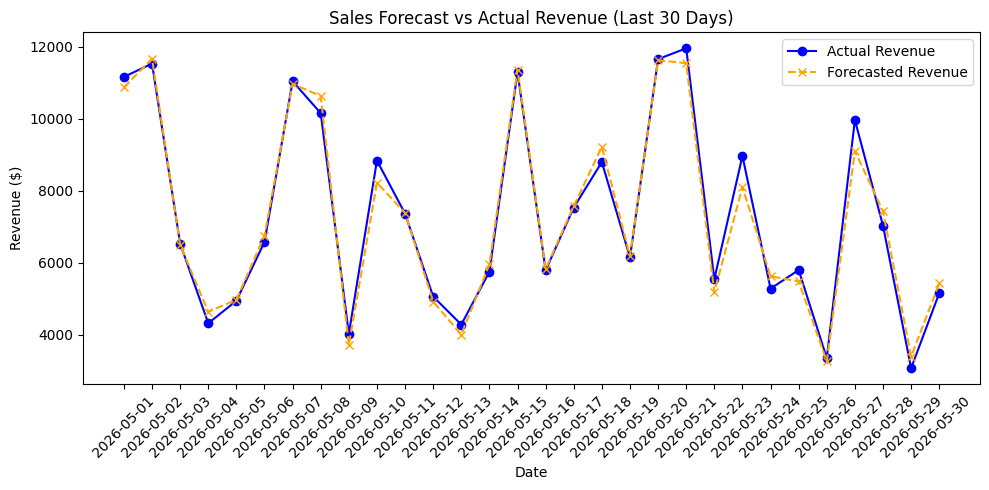

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

excel_file = "sales_forecast.xlsx"
df = pd.read_excel(excel_file)

X = df[["marketing_budget", "active_promotions"]]
y = df["actual_revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

df["predicted_revenue"] = model.predict(X).round(2)
df["forecast_error"] = (df["actual_revenue"] - df["predicted_revenue"]).round(2)

with pd.ExcelWriter(
    excel_file, engine="openpyxl", mode="a", if_sheet_exists="replace"
) as writer:
    df.to_excel(writer, sheet_name="Model_Predictions", index=False)

y_pred = model.predict(X_test)
print(f"R-squared Score: {r2_score(y_test, y_pred):.2f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")

plt.figure(figsize=(10, 5))
plt.plot(
    df["date"][-30:],
    df["actual_revenue"][-30:],
    label="Actual Revenue",
    marker="o",
    color="blue",
)
plt.plot(
    df["date"][-30:],
    df["predicted_revenue"][-30:],
    label="Forecasted Revenue",
    linestyle="--",
    marker="x",
    color="orange",
)
plt.xticks(rotation=45)
plt.title("Sales Forecast vs Actual Revenue (Last 30 Days)")
plt.ylabel("Revenue ($)")
plt.xlabel("Date")
plt.legend()
plt.tight_layout()
plt.show()


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
